# TMLR figures and tables

Reads `results/*_results.csv` and writes every figure and results table of the paper to `figures/tmlr/`. Datasets are the statistical unit: per-dataset log-ratios, Wilcoxon signed-rank tests with Holm correction, and Friedman mean ranks. Each section also prints the numbers quoted in the paper text ("numbers for the text").

Tables are written as `.tex` and use the paper's macros (`\WS`, `\Hd{}`, `\sig{}`, `\SGT`, ...). Figures are drawn at their final print width in the paper's font (Latin Modern), so include them at the width stated in each section without further scaling.

| Output | Paper |
|---|---|
| `baseline.tex` | Table: baselines vs noise floor (RQ1) |
| `imputation.tex` | Table: imputers vs SGT and RS (RQ2) |
| `pairwise_imputers.pdf` | Figure: pairwise consensus-rank differences (appendix), `width=0.6\linewidth` |
| `growth.tex` | Table: growth of topological vs raw error by family, with retention (RQ3, RQ4) |
| `mechanism.tex` | Table: effect of the missingness mechanism, with decomposition of the retention (RQ5) |
| `filtration.tex` | Table: robustness of VR, DTM and KD by family (RQ6) |
| `kd.tex` | Table: scale of the kernel-distance filtration (appendix, RQ6) |
| `redundancy_retention.pdf` | Figure: feature redundancy vs retention (RQ4), `width=0.62\linewidth` |
| `growth_by_family.pdf` | Figure: growth of topological vs raw error, synthetic and real-world (RQ3, RQ4), `width=\linewidth` |

## Setup

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.constants import DATASET_TYPE_MAP

RES, OUT = ROOT / 'results', ROOT / 'figures' / 'tmlr'
OUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', category=RuntimeWarning)

MCAR, MAR, MNAR = 'missing_completely_at_random', 'missing_at_random', 'missing_not_at_random'
SGT, CCA, RS = 'shuffled_ground_truth', 'complete_case_analysis', 'random_subsample'
VR = 'vietoris_rips'
IMPUTERS = {'constant_imputation': 'Constant', 'mean_imputation': 'Mean', 'median_imputation': 'Median',
            'k_nearest_neighbors_imputation': 'kNN', 'random_forest_imputation': 'RF', 'mice_imputation': 'MICE',
            'gain_imputation': 'GAIN', 'tabcsdi_imputation': 'TabCSDI', 'otimpute_imputation': 'OT-Impute'}
TOPO = ['wasserstein_distance', 'bottleneck_distance', 'l2_distance_landscape', 'l2_distance_image']
DIMS = [0, 1, 2]
FEATURES = [(m, d) for m in TOPO for d in DIMS]

# LaTeX names (paper macros)
MACRO = {'wasserstein_distance': r'\WS', 'bottleneck_distance': r'\BN',
         'l2_distance_landscape': r'\PL', 'l2_distance_image': r'\PI'}
LABEL_TOPO = dict(zip(TOPO, ['WS', 'BN', 'PL', 'PI']))
TEX_NAME = {'kNN': r'$k$NN'}


def family(dataset):
    return 'Synthetic' if DATASET_TYPE_MAP.get(dataset) == 'manifold' else 'Real-world'

### Style

In [2]:
# page geometry (inches, 1in margins = TMLR text block)
FULL = 6.5
WIDE = 0.75 * FULL      # canvas of the pairwise figure; the tight bbox of its square tiles yields a ~3.6 in PDF

# font sizes (pt at print size)
BASE, SMALL = 9, 8

# ink & chrome
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, AXIS = '#e1e0d9', '#c3c2b7'

# fixed entity colours (first four validated as colour-blind safe for all pairs on white)
BLUE, ORANGE, AQUA, VIOLET = '#2a78d6', '#eb6834', '#1baf7a', '#4a3aa7'
FAMILY_COLOR = {'Synthetic': BLUE, 'Real-world': ORANGE}
MECHANISM_COLOR = {'MCAR': BLUE, 'MAR': ORANGE, 'MNAR': AQUA}
DISTANCE_COLOR = dict(zip(TOPO, [BLUE, ORANGE, AQUA, VIOLET]))

# diverging blue <-> red with a grey midpoint
DIVERGING = LinearSegmentedColormap.from_list('tmlr_div', [
    '#184f95', '#256abf', '#3987e5', '#86b6ef', '#cde2fb', '#f0efec',
    '#f9d4d3', '#f0a09f', '#e34948', '#c13332', '#97201f'])

# Latin Modern ships optical sizes 5-17 under one family name; keep the 10 pt cut (LaTeX body text)
font_manager.fontManager.ttflist = [f for f in font_manager.fontManager.ttflist
                                    if f.name != 'Latin Modern Roman' or Path(f.fname).name.startswith('lmroman10-')]
font_manager._get_font.cache_clear()

mpl.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Latin Modern Roman', 'DejaVu Serif'], 'mathtext.fontset': 'cm',
    'font.size': BASE, 'axes.titlesize': BASE, 'axes.labelsize': BASE,
    'xtick.labelsize': BASE - 0.5, 'ytick.labelsize': BASE - 0.5, 'legend.fontsize': BASE - 0.5,
    'text.color': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.5, 'axes.axisbelow': True,
    'lines.linewidth': 1.2, 'lines.markersize': 4, 'legend.frameon': False,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})


def minus(s):
    """Typographic minus sign."""
    return s.replace('-', '−')


def save_fig(fig, name):
    fig.savefig(OUT / f'{name}.pdf')
    print(OUT / f'{name}.pdf')


def save_tex(tex, name):
    """Write the table verbatim (no newline added)."""
    (OUT / f'{name}.tex').write_text(tex)
    print(OUT / f'{name}.tex')
    display(Markdown(f'```latex\n{tex}\n```'))

### Statistics

In [3]:
ALPHA = 0.05


def holm(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); m = ~np.isnan(p)
    if m.any():
        out[m] = multipletests(p[m], method='holm')[1]
    return out


def stars(p):
    return '' if pd.isna(p) else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < ALPHA else ''


def signed_rank(x, alternative='two-sided'):
    """Wilcoxon signed-rank p-value on paired differences (one value per dataset)."""
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 5 or np.allclose(x, 0):
        return np.nan
    return stats.wilcoxon(x, alternative=alternative, zero_method='wilcox').pvalue


def mean_ranks(M):
    """Friedman mean ranks of a datasets x methods matrix (lower = better)."""
    return M.dropna().rank(axis=1).mean().sort_values()


def pairwise_wilcoxon(M):
    """Holm-corrected pairwise Wilcoxon on a datasets x methods matrix."""
    cols, rows = list(M.columns), []
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            rows.append(dict(a=a, b=b, diff=np.nanmedian(M[a] - M[b]), p=signed_rank((M[a] - M[b]).values)))
    out = pd.DataFrame(rows); out['p_holm'] = holm(out.p)
    return out


def breakeven(g, col):
    """Smallest missing rate (log-interpolated) at which log-ratio `col` crosses 0; inf if never."""
    g = g.sort_values('missing_rate'); x = np.log(g.missing_rate.values); y = g[col].values
    if y[0] > 0:
        return g.missing_rate.iloc[0]
    for i in range(1, len(y)):
        if y[i] > 0 and y[i - 1] <= 0:
            return float(np.exp(x[i - 1] + (x[i] - x[i - 1]) * (-y[i - 1]) / (y[i] - y[i - 1])))
    return np.inf


def num(v, p=None, d=2):
    """LaTeX number with significance stars."""
    return f'{v:.{d}f}' + (rf'\sig{{{stars(p)}}}' if p is not None and stars(p) else '')


def pad_column(cells):
    """Left-pad numbers with \\phantom{0} so a column aligns on the decimal point."""
    width = max(len(c.split('.')[0]) for c in cells if '.' in c)
    return [r'\phantom{' + '0' * (width - len(c.split('.')[0])) + '}' + c
            if '.' in c and len(c.split('.')[0]) < width else c for c in cells]


def align_rows(rows, indent=8):
    """Join table rows with ' & ', padding every column but the last to a common width."""
    widths = [max(len(r[j]) for r in rows) for j in range(len(rows[0]) - 1)]
    return '\n'.join(' ' * indent + ' & '.join([c.ljust(w) for c, w in zip(r, widths)] + [r[-1]]) + r' \\'
                     for r in rows)

### Data

Long format, one row per (dataset, mechanism, rate, method, filtration, dimension, distance). Exact zeros are kept finite by adding 1% of the median positive value of each (dataset, filtration, distance, dimension) group, computed over all topological result files.

In [4]:
ID = ['dataset', 'missingness_type', 'missing_rate', 'imputation_method', 'tda_method', 'dimension']
TOPO_FILES = ['baseline', 'topological_metrics', 'topological_metrics_filtration', 'topological_metrics_mr']


def to_long(df):
    return df.melt(id_vars=[c for c in ID if c in df], value_vars=[m for m in TOPO if m in df],
                   var_name='metric', value_name='value')


raw = {f: to_long(pd.read_csv(RES / f'{f}_results.csv')) for f in TOPO_FILES}
allv = pd.concat(raw.values())
EPS = (allv[allv.value > 0].groupby(['dataset', 'tda_method', 'metric', 'dimension']).value.median() * 0.01).rename('eps')


def smooth(df):
    df = df.join(EPS, on=['dataset', 'tda_method', 'metric', 'dimension'])
    df['v'] = df.value + df.eps.fillna(0)
    return df.drop(columns='eps')


base, imp = smooth(raw['baseline']), smooth(raw['topological_metrics'])
print({k: v.dataset.nunique() for k, v in raw.items()})

{'baseline': 18, 'topological_metrics': 18, 'topological_metrics_filtration': 18, 'topological_metrics_mr': 18}


## Table: baselines relative to the noise floor (RQ1)

Per (dataset, rate, distance, dimension): $\log(d_\mathrm{SGT}/d_\mathrm{RS})$ and $\log(d_\mathrm{CCA}/d_\mathrm{RS})$, VR, MAR. Entries: median over datasets; stars: two-sided Wilcoxon, Holm over the 12 measures of each column. $\mathrm{MR}^*$: median over datasets of the rate at which $d_\mathrm{SGT}$ first exceeds $d_\mathrm{RS}$ (log-interpolated over all 13 rates).

Numbers for the text: $\mathrm{MR}^*$ by family (log-ratio averaged over the 12 measures, break-even per mechanism, median over mechanisms per dataset), and the effect of the mechanism on $d_\mathrm{SGT}/d_\mathrm{RS}$ (Friedman per distance with dimensions pooled, at 10% and 25%, Holm over the 8 tests).

In [5]:
B = (base[(base.tda_method == VR) & (base.missingness_type == MAR)]
     .pivot_table(index=['dataset', 'missing_rate', 'metric', 'dimension'], columns='imputation_method', values='v')
     .reset_index())
B['lr_sgt_rs'] = np.log(B[SGT] / B[RS])
B['lr_cca_rs'] = np.log(B[CCA] / B[RS])

COLS = [('lr_sgt_rs', r) for r in (5, 10, 25, 40)] + [('lr_cca_rs', r) for r in (5, 10, 25)]
columns = []
for col, rate in COLS:
    xs = [B[(B.metric == m) & (B.dimension == d) & (B.missing_rate == rate)][col] for m, d in FEATURES]
    ps = holm([signed_rank(x.values) for x in xs])
    columns.append(pad_column([num(np.exp(np.median(x.dropna())), p) for x, p in zip(xs, ps)]))

mr_star = [np.median(B[(B.metric == m) & (B.dimension == d)].groupby('dataset').apply(lambda g: breakeven(g, 'lr_sgt_rs')))
           for m, d in FEATURES]
columns.append(pad_column([f'{v:.1f}\\%' if np.isfinite(v) else '$>$40\\%' for v in mr_star]))

body = '\n'.join(f'        {MACRO[m]} & \\Hd{{{d}}} & ' + ' & '.join(c[i] for c in columns) + r' \\'
                 for i, (m, d) in enumerate(FEATURES))

save_tex(rf"""\begin{{table}}[t]
    \centering
    \caption{{Baseline performance relative to noise floor (MAR, {B.dataset.nunique()} datasets). Entries show median ratios $d_{{\SGT}} / d_{{\RS}}$ and $d_{{\CCA}} / d_{{\RS}}$ with significance stars. $\MR^*$: missing-rate threshold where \SGT\ exceeds \RS.}}
    \label{{tab:baseline}}
    \small
    \setlength{{\tabcolsep}}{{10pt}}
    \begin{{tabular}}{{r@{{\,}}l cccc ccc c}}
        \toprule
        \multicolumn{{2}}{{c}}{{}} & \multicolumn{{4}}{{c}}{{$d_{{\SGT}}/d_{{\RS}}$}} & \multicolumn{{3}}{{c}}{{$d_{{\CCA}}/d_{{\RS}}$}} & \\
        \cmidrule(lr){{3-6}}\cmidrule(lr){{7-9}}
        \multicolumn{{2}}{{c}}{{Measure}} & 5\% & 10\% & 25\% & 40\% & 5\% & 10\% & 25\% & $\MR^*$ \\
        \midrule
{body}
        \bottomrule
    \end{{tabular}}
\end{{table}}""", 'baseline')

# numbers for the text (all mechanisms)
BM = (base[base.tda_method == VR]
      .pivot_table(index=['dataset', 'missingness_type', 'missing_rate', 'metric', 'dimension'], columns='imputation_method', values='v')
      .reset_index())
BM['lr_sgt_rs'] = np.log(BM[SGT] / BM[RS])
pooled = BM.groupby(['dataset', 'missingness_type', 'missing_rate']).lr_sgt_rs.mean().reset_index()
mr_ds = pooled.groupby(['dataset', 'missingness_type']).apply(lambda g: breakeven(g, 'lr_sgt_rs')).groupby('dataset').median()
for F in ('Synthetic', 'Real-world'):
    x = mr_ds[mr_ds.index.map(family) == F]
    print(f'MR* {F}: median {x.median():.1f}% (range {x.min():.1f}-{x.max():.1f}%, n = {len(x)})')
g = BM.groupby(['dataset', 'missingness_type', 'missing_rate', 'metric']).lr_sgt_rs.mean().reset_index()
p_mech = holm([stats.friedmanchisquare(*g[(g.metric == m) & (g.missing_rate == r)]
                                       .pivot(index='dataset', columns='missingness_type', values='lr_sgt_rs').T.values).pvalue
               for m in TOPO for r in (10, 25)])
print(f'SGT/RS across mechanisms (Friedman, Holm over {len(p_mech)}): max p = {p_mech.max():.3f}')

/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/baseline.tex


```latex
\begin{table}[t]
    \centering
    \caption{Baseline performance relative to noise floor (MAR, 18 datasets). Entries show median ratios $d_{\SGT} / d_{\RS}$ and $d_{\CCA} / d_{\RS}$ with significance stars. $\MR^*$: missing-rate threshold where \SGT\ exceeds \RS.}
    \label{tab:baseline}
    \small
    \setlength{\tabcolsep}{10pt}
    \begin{tabular}{r@{\,}l cccc ccc c}
        \toprule
        \multicolumn{2}{c}{} & \multicolumn{4}{c}{$d_{\SGT}/d_{\RS}$} & \multicolumn{3}{c}{$d_{\CCA}/d_{\RS}$} & \\
        \cmidrule(lr){3-6}\cmidrule(lr){7-9}
        \multicolumn{2}{c}{Measure} & 5\% & 10\% & 25\% & 40\% & 5\% & 10\% & 25\% & $\MR^*$ \\
        \midrule
        \WS & \Hd{0} & 0.81 & 1.55 & 3.86\sig{**} & \phantom{0}6.43\sig{***} & 2.19\sig{***} & 3.66\sig{***} & \phantom{0}5.30\sig{**} & \phantom{0}6.2\% \\
        \WS & \Hd{1} & 0.91 & 1.61\sig{*} & 4.45\sig{***} & \phantom{0}7.53\sig{***} & 1.42\sig{*} & 2.15\sig{***} & \phantom{0}3.29\sig{**} & \phantom{0}5.7\% \\
        \WS & \Hd{2} & 0.89 & 1.48\sig{*} & 4.77\sig{***} & \phantom{0}9.68\sig{***} & 0.99 & 1.54\sig{**} & \phantom{0}2.03\sig{**} & \phantom{0}5.5\% \\
        \BN & \Hd{0} & 0.97 & 1.11 & 1.32 & \phantom{0}1.50\sig{*} & 1.90\sig{*} & 2.01\sig{**} & \phantom{0}2.42\sig{*} & \phantom{0}3.2\% \\
        \BN & \Hd{1} & 1.07 & 1.05 & 1.31 & \phantom{0}1.84\sig{**} & 1.09 & 1.21 & \phantom{0}1.59\sig{**} & \phantom{0}2.3\% \\
        \BN & \Hd{2} & 1.03 & 1.17 & 1.32 & \phantom{0}1.67\sig{**} & 1.00 & 1.17 & \phantom{0}1.37 & \phantom{0}4.1\% \\
        \PL & \Hd{0} & 0.80 & 1.01 & 6.20 & 14.65\sig{*} & 3.31 & 1.69 & 25.64 & \phantom{0}8.1\% \\
        \PL & \Hd{1} & 1.32 & 1.41 & 1.91\sig{*} & \phantom{0}2.52\sig{**} & 1.31 & 1.70\sig{*} & \phantom{0}1.76\sig{*} & \phantom{0}1.8\% \\
        \PL & \Hd{2} & 1.17 & 1.33 & 1.34 & \phantom{0}1.79\sig{**} & 1.09 & 1.11 & \phantom{0}1.30 & \phantom{0}2.2\% \\
        \PI & \Hd{0} & 0.23\sig{**} & 0.41\sig{**} & 0.64 & \phantom{0}0.85 & 1.67\sig{**} & 2.48\sig{***} & \phantom{0}4.23\sig{**} & 29.8\% \\
        \PI & \Hd{1} & 0.36\sig{**} & 0.82 & 2.39 & \phantom{0}3.30\sig{**} & 1.47\sig{*} & 2.69\sig{***} & \phantom{0}3.72\sig{**} & 12.3\% \\
        \PI & \Hd{2} & 0.64 & 1.00 & 4.02 & \phantom{0}7.86\sig{***} & 1.64\sig{*} & 2.83\sig{***} & \phantom{0}3.57\sig{**} & \phantom{0}9.7\% \\
        \bottomrule
    \end{tabular}
\end{table}
```

MR* Synthetic: median 4.3% (range 4.3-4.8%, n = 3)
MR* Real-world: median 12.9% (range 1.0-37.6%, n = 15)
SGT/RS across mechanisms (Friedman, Holm over 8): max p = 0.011


## Table: imputers relative to SGT and RS (RQ2)

VR, MAR, 5/10/25%. Per dataset, the log-ratio $\log(d_\mathrm{imp}/d_\mathrm{ref})$ is averaged over dimensions and rates; entries are the median over datasets. Stars: Wilcoxon, one-sided ($d_\mathrm{imp} < d_\mathrm{SGT}$) in the left block and two-sided in the right block, Holm over the 36 tests of each block. Mean rank: imputers are ranked within every (dataset, rate, distance, dimension) cell, averaged per dataset (consensus rank), and re-ranked across datasets (Friedman mean rank), over all datasets and within each family.

Numbers for the text: Friedman test of the consensus ranks overall and per distance (dimensions pooled), the best imputer per distance, and the Spearman correlation of the mean consensus ranks on synthetic and real-world data.

In [6]:
Q = (pd.concat([imp[(imp.missingness_type == MAR) & (imp.tda_method == VR)],
                base[(base.missingness_type == MAR) & (base.tda_method == VR) & base.missing_rate.isin([5, 10, 25])]])
     .pivot_table(index=['dataset', 'missing_rate', 'metric', 'dimension'], columns='imputation_method', values='v'))
IMP = [m for m in IMPUTERS if m in Q]

R_cons = Q[IMP].dropna().rank(axis=1).groupby('dataset').mean().rename(columns=IMPUTERS)
fams = R_cons.index.map(family)
ranks = {'All': mean_ranks(R_cons),
         'Synthetic': mean_ranks(R_cons[fams == 'Synthetic']),
         'Real-world': mean_ranks(R_cons[fams == 'Real-world'])}
n_fam = {F: int((fams == F).sum()) for F in ('Synthetic', 'Real-world')}
order = list(ranks['All'].index)

ratio, pval = {}, {}
for ref, alt in [(SGT, 'less'), (RS, 'two-sided')]:
    lr = np.log(Q[IMP].div(Q[ref], axis=0)).groupby(['dataset', 'metric']).mean().rename(columns=IMPUTERS)
    keys = [(ref, name, met) for name in IMPUTERS.values() for met in TOPO]
    xs = [lr.xs(met, level='metric')[name].dropna() for _, name, met in keys]
    ratio.update({k: np.exp(x.median()) for k, x in zip(keys, xs)})
    pval.update(zip(keys, holm([signed_rank(x.values, alternative=alt) for x in xs])))

best = {k: r.min() for k, r in ranks.items()}
rows = []
for name in order:
    rk = [rf'\textbf{{{ranks[k][name]:.2f}}}' if np.isclose(ranks[k][name], best[k]) else f'{ranks[k][name]:.2f}'
          for k in ('All', 'Synthetic', 'Real-world')]
    rt = [num(ratio[(ref, name, met)], pval[(ref, name, met)]) for ref in (SGT, RS) for met in TOPO]
    rows.append([TEX_NAME.get(name, name)] + rk + rt)
dist = ' & '.join(MACRO[m] for m in TOPO)

save_tex(rf"""\begin{{table}}[t]
    \centering
    \caption{{Imputation performance relative to $d_{{\SGT}}$ and $d_{{\RS}}$ (VR, MAR, 5/10/25\%, {len(R_cons)} datasets). Stars: Wilcoxon (one-sided vs.\ \SGT, two-sided vs.\ \RS), Holm-corrected.}}
    \label{{tab:imputation}}
    \small
    \setlength{{\tabcolsep}}{{9.75pt}}
    \begin{{tabular}}{{l ccc cccc cccc}}
        \toprule
        & \multicolumn{{3}}{{c}}{{Mean rank $\downarrow$}} & \multicolumn{{4}}{{c}}{{$d_{{\TOPO}} / d_{{\SGT}}$}} & \multicolumn{{4}}{{c}}{{$d_{{\TOPO}} / d_{{\RS}}$}} \\
        \cmidrule(lr){{2-4}}\cmidrule(lr){{5-8}}\cmidrule(lr){{9-12}}
        Imputer & All & Syn. & Real & {dist} & {dist} \\
        \midrule
{align_rows(rows)}
        \bottomrule
    \end{{tabular}}
\end{{table}}""", 'imputation')

# numbers for the text
print(f'Friedman (consensus): p = {stats.friedmanchisquare(*R_cons.T.values).pvalue:.2g}')
for met in TOPO:
    Rm = Q[IMP].xs(met, level='metric').dropna().rank(axis=1).groupby('dataset').mean().rename(columns=IMPUTERS)
    print(f'{LABEL_TOPO[met]}: Friedman p = {stats.friedmanchisquare(*Rm.T.values).pvalue:.2g}, best {mean_ranks(Rm).index[0]}')
sp = stats.spearmanr(R_cons[fams == 'Synthetic'].mean()[order], R_cons[fams == 'Real-world'].mean()[order])
print(f'synthetic vs real-world ranking: r_s = {sp.statistic:.2f} (p = {sp.pvalue:.3f}); '
      f"best {ranks['Synthetic'].index[0]} (synthetic), {ranks['Real-world'].index[0]} (real-world)")

/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/imputation.tex


```latex
\begin{table}[t]
    \centering
    \caption{Imputation performance relative to $d_{\SGT}$ and $d_{\RS}$ (VR, MAR, 5/10/25\%, 18 datasets). Stars: Wilcoxon (one-sided vs.\ \SGT, two-sided vs.\ \RS), Holm-corrected.}
    \label{tab:imputation}
    \small
    \setlength{\tabcolsep}{9.75pt}
    \begin{tabular}{l ccc cccc cccc}
        \toprule
        & \multicolumn{3}{c}{Mean rank $\downarrow$} & \multicolumn{4}{c}{$d_{\TOPO} / d_{\SGT}$} & \multicolumn{4}{c}{$d_{\TOPO} / d_{\RS}$} \\
        \cmidrule(lr){2-4}\cmidrule(lr){5-8}\cmidrule(lr){9-12}
        Imputer & All & Syn. & Real & \WS & \BN & \PL & \PI & \WS & \BN & \PL & \PI \\
        \midrule
        RF        & \textbf{2.22} & 2.00          & \textbf{2.27} & 0.38\sig{***} & 0.76\sig{**} & 0.67        & 0.43\sig{**} & 0.72\sig{**} & 0.92 & 0.53 & 0.32\sig{***} \\
        $k$NN     & 3.22          & 3.33          & 3.20          & 0.48\sig{**}  & 0.73\sig{**} & 0.69\sig{*} & 0.44\sig{*}  & 0.84         & 0.87 & 0.63 & 0.33\sig{***} \\
        MICE      & 3.94          & \textbf{1.00} & 4.53          & 0.56\sig{***} & 0.80\sig{**} & 0.80        & 0.64         & 0.77         & 0.89 & 0.66 & 0.39 \\
        OT-Impute & 4.39          & 4.67          & 4.33          & 0.43\sig{*}   & 0.78\sig{**} & 0.58\sig{*} & 0.50         & 0.89         & 0.89 & 0.58 & 0.44\sig{**} \\
        Constant  & 5.61          & 6.00          & 5.53          & 0.51\sig{*}   & 0.91         & 0.86        & 0.61         & 1.02         & 1.03 & 1.41 & 0.44 \\
        GAIN      & 5.78          & 4.00          & 6.13          & 0.78\sig{**}  & 0.85\sig{**} & 0.94        & 0.76\sig{*}  & 1.05         & 0.96 & 0.70 & 0.55 \\
        Median    & 5.89          & 7.67          & 5.53          & 0.54\sig{**}  & 0.91         & 0.87        & 0.61         & 1.00         & 1.05 & 1.56 & 0.41 \\
        Mean      & 6.56          & 7.33          & 6.40          & 0.54\sig{*}   & 0.94         & 0.94        & 0.68         & 1.05         & 1.05 & 1.60 & 0.46 \\
        TabCSDI   & 7.39          & 9.00          & 7.07          & 0.85          & 1.26         & 1.63        & 1.15         & 1.33         & 1.36 & 2.19 & 1.09 \\
        \bottomrule
    \end{tabular}
\end{table}
```

Friedman (consensus): p = 8.9e-09
WS: Friedman p = 8.6e-08, best RF
BN: Friedman p = 0.00044, best MICE
PL: Friedman p = 6.8e-06, best RF
PI: Friedman p = 8.2e-06, best RF
synthetic vs real-world ranking: r_s = 0.82 (p = 0.007); best MICE (synthetic), RF (real-world)


## Figure: pairwise consensus-rank differences (appendix)

Median over datasets of the consensus-rank difference (row − column); upper triangle only, imputers in mean-rank order. Bold with stars: Holm-corrected Wilcoxon over the 36 pairs. No title; the caption goes in LaTeX. Drawn on a `0.75\linewidth` canvas; the square tiles and tight bounding box leave a ~3.6 in PDF, so include with `width=0.6\linewidth` (close to print size).

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/pairwise_imputers.pdf


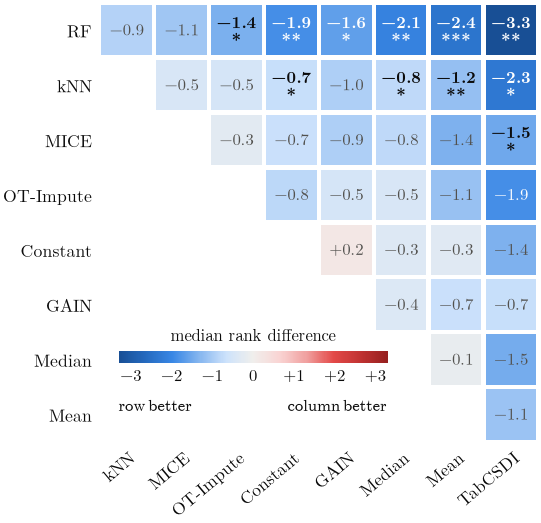

significant pairs (Holm): 11 of 36


In [7]:
pw = pairwise_wilcoxon(R_cons[order])
k = len(order)
D = pd.DataFrame(np.nan, index=order, columns=order)
P = D.copy()
for _, r in pw.iterrows():
    D.loc[r.a, r.b], D.loc[r.b, r.a] = r['diff'], -r['diff']
    P.loc[r.a, r.b] = P.loc[r.b, r.a] = r.p_holm
lim = np.round(np.nanmax(np.abs(D.values)), 1)
norm = plt.Normalize(-lim, lim)

fig, ax = plt.subplots(figsize=(WIDE, WIDE * 0.78))
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)

GAP = 0.04   # white gap between tiles
for i in range(k):
    for j in range(i + 1, k):
        v, p = D.iloc[i, j], P.iloc[i, j]
        sig = p < ALPHA
        fill = DIVERGING(norm(v))
        ax.add_patch(plt.Rectangle((j - 0.5 + GAP, i - 0.5 + GAP), 1 - 2 * GAP, 1 - 2 * GAP, facecolor=fill, lw=0))
        dark = 0.2126 * fill[0] + 0.7152 * fill[1] + 0.0722 * fill[2] < 0.6
        ink = 'white' if dark else INK if sig else INK2
        label = minus(f'{v:+.1f}')
        if sig:
            ax.text(j, i + 0.02, label, ha='center', va='bottom', fontsize=SMALL, color=ink, fontweight='bold')
            ax.text(j, i + 0.04, stars(p), ha='center', va='top', fontsize=SMALL, color=ink, fontweight='bold')
        else:
            ax.text(j, i, label, ha='center', va='center', fontsize=SMALL, color=ink)

ax.set_xticks(range(1, k), order[1:], rotation=40, ha='right', rotation_mode='anchor')
ax.set_yticks(range(k - 1), order[:-1])
ax.set_xlim(0.5, k - 0.5); ax.set_ylim(k - 1.5, -0.5)
ax.set_aspect('equal')
ax.tick_params(length=0)

# colour bar in the empty lower-left triangle; end labels in math text for thin spaces (\\,) (Median and Mean rows)
LEG_X, LEG_Y, LEG_W = 0.85, 5.85, 4.9   # colour bar position in data units (x: columns, y: rows)
cax = ax.inset_axes([LEG_X, LEG_Y, LEG_W, 0.22], transform=ax.transData)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=DIVERGING), cax=cax, orientation='horizontal',
                  ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=SMALL, pad=2)
cb.ax.set_xticklabels([minus(f'{t:+d}') if t else '0' for t in range(-3, 4)])
ax.text(LEG_X + LEG_W / 2, LEG_Y - 0.13, 'median rank difference', ha='center', va='bottom', fontsize=SMALL, color=INK)
ax.text(LEG_X, LEG_Y + 1.0, r'$\mathrm{row}\,\mathrm{better}$', ha='left', va='center', fontsize=SMALL, color=INK)
ax.text(LEG_X + LEG_W, LEG_Y + 1.0, r'$\mathrm{column}\,\mathrm{better}$', ha='right', va='center', fontsize=SMALL, color=INK)

save_fig(fig, 'pairwise_imputers')
plt.show()
print(f'significant pairs (Holm): {(pw.p_holm < ALPHA).sum()} of {len(pw)}')

## Figure: growth of topological vs raw error, by family (RQ3, RQ4)

$k$NN imputation, VR, MAR (as in RQ1/RQ2; mechanisms are compared in RQ5), 13 missing rates (1–40%). Each curve (dataset × measure) is divided by its own value at 1%; lines show the median over datasets and bands (real-world only; an IQR over three manifolds would not be a spread) the inter-quartile range. Both axes are logarithmic, so the slope is the elasticity $\beta$. RMSE (dashed) is the reference, MAE (dotted) the second raw error. Rows: synthetic manifolds and real-world data; columns: homology dimension. No title; the caption goes in LaTeX. Include with `width=\linewidth`.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/growth_by_family.pdf


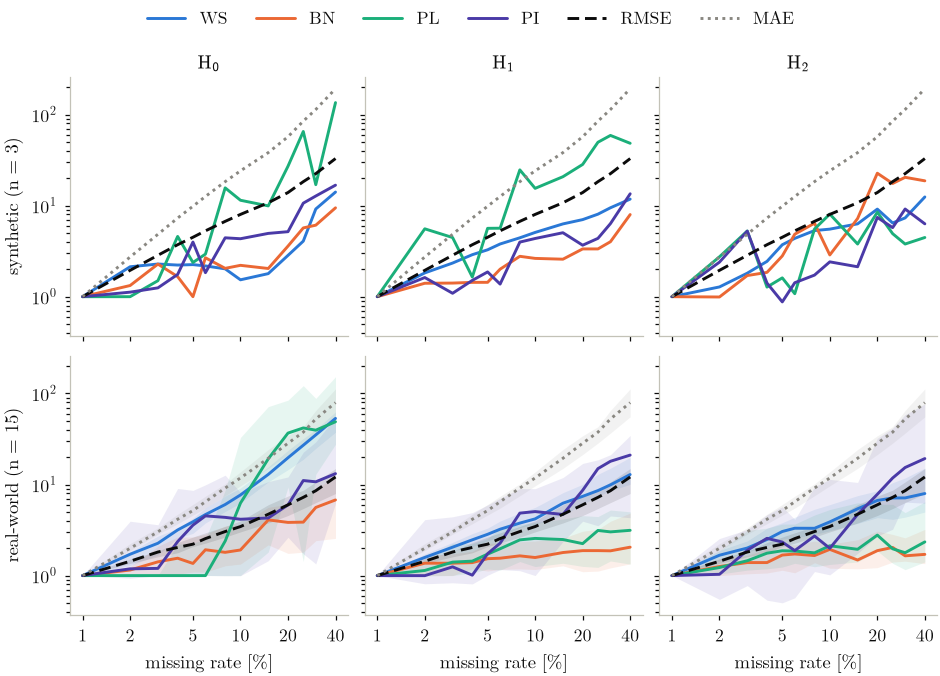

In [8]:
KNN = 'k_nearest_neighbors_imputation'
RAW = {'root_mean_square_error': 'RMSE', 'mean_absolute_error': 'MAE'}

mr = smooth(raw['topological_metrics_mr'])
mr = mr[(mr.tda_method == VR) & (mr.imputation_method == KNN) & (mr.missingness_type == MAR)].assign(measure=lambda d: d.metric)
cmp_ = pd.read_csv(RES / 'comparison_metrics_results.csv')
cmp_ = (cmp_[(cmp_.imputation_method == KNN) & (cmp_.missingness_type == MAR)]
        .melt(id_vars=['dataset', 'missingness_type', 'missing_rate'], value_vars=list(RAW), var_name='measure', value_name='v')
        .assign(dimension=-1))
common = set(mr.dataset) & set(cmp_.dataset)
G = pd.concat([mr[['dataset', 'missingness_type', 'missing_rate', 'measure', 'dimension', 'v']], cmp_])
G = G[G.dataset.isin(common)]

# each curve relative to its own value at the lowest rate
key = ['dataset', 'missingness_type', 'measure', 'dimension']
first = G[G.missing_rate == G.missing_rate.min()].set_index(key).v.rename('v1')
G = G.join(first, on=key)
G['rel'] = G.v / G.v1
G['family'] = G.dataset.map(family)
n_ds = G.groupby('family').dataset.nunique()

SERIES = ([(m, LABEL_TOPO[m], DISTANCE_COLOR[m], '-') for m in TOPO]
          + [('root_mean_square_error', 'RMSE', INK, (0, (4, 2))), ('mean_absolute_error', 'MAE', MUTED, (0, (1, 1.5)))])
RATES = [1, 2, 5, 10, 20, 40]

fig, axes = plt.subplots(2, 3, figsize=(FULL, 4.4), sharex=True, sharey=True)
for r, fam in enumerate(['Synthetic', 'Real-world']):
    for c, d in enumerate(DIMS):
        ax = axes[r, c]
        for m, lab, col, ls in SERIES:
            g = G[(G.family == fam) & (G.measure == m) & (G.dimension.isin([d, -1]))].groupby('missing_rate').rel
            med = g.median()
            if fam == 'Real-world':   # an IQR over three datasets is not a spread; synthetic shows the median only
                ax.fill_between(med.index, g.quantile(.25), g.quantile(.75), color=col, alpha=0.10, lw=0)
            ax.plot(med.index, med.values, color=col, ls=ls, lw=1.4, label=lab, solid_capstyle='round')
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xticks(RATES, [str(x) for x in RATES]); ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
        ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
        ax.grid(which='major', axis='both')
        if r == 0:
            ax.set_title(rf'$\mathrm{{H}}_{d}$', pad=4)
        if r == 1:
            ax.set_xlabel('missing rate [%]')
        if c == 0:
            ax.set_ylabel(f'{"synthetic" if fam == "Synthetic" else "real-world"} (n = {n_ds[fam]})')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=6, bbox_to_anchor=(0.5, 1.06), handlelength=2.2, columnspacing=1.6)
fig.tight_layout(h_pad=0.8, w_pad=0.6)
save_fig(fig, 'growth_by_family')
plt.show()

## Table: growth of topological vs raw error, by family (RQ3, RQ4)

Elasticity $\beta$: slope of $\log(\text{error})$ on $\log(\text{rate})$ over 1–40% per dataset (MAR). $\Delta\beta = \beta_\text{topo} - \beta_\text{RMSE}$ within each dataset (negative = grows more slowly than RMSE). Real-world: median, two-sided Wilcoxon (Holm over the 12 measures) and rank-biserial $r$; synthetic: median only ($n = 3$ cannot reach significance). "Slower": datasets with $\Delta\beta < 0$. $\rho = d_\mathrm{kNN}/d_\mathrm{SGT}$: retention, geometric mean over rates per dataset, median over datasets (1 = no better than shuffled data).

Writes `growth.tex`.

In [9]:
def rank_biserial(x):
    x = np.asarray(x, float); x = x[~np.isnan(x) & (x != 0)]
    rk = stats.rankdata(np.abs(x))
    return (rk[x > 0].sum() - rk[x < 0].sum()) / rk.sum()


def elasticity(g):
    x, y = np.log(g.missing_rate.values), np.log(g.v.values)
    ok = np.isfinite(x) & np.isfinite(y)
    return np.polyfit(x[ok], y[ok], 1)[0] if ok.sum() >= 3 else np.nan


# beta per dataset and measure (MAR); RMSE stored under dimension -1
beta = (G.groupby(['dataset', 'missingness_type', 'measure', 'dimension']).apply(elasticity)
        .groupby(['dataset', 'measure', 'dimension']).mean())
b_rmse = beta.xs(('root_mean_square_error', -1), level=('measure', 'dimension'))
b_mae = beta.xs(('mean_absolute_error', -1), level=('measure', 'dimension'))

# retention rho = d_kNN / d_SGT at the same rate (MAR; log, mean over rates)
sgt = base[(base.tda_method == VR) & (base.imputation_method == SGT) & (base.missingness_type == MAR)].set_index(
    ['dataset', 'missingness_type', 'missing_rate', 'metric', 'dimension']).v.rename('sgt')
K = mr.set_index(['dataset', 'missingness_type', 'missing_rate', 'metric', 'dimension']).v.rename('knn')
rho = np.log(pd.concat([K, sgt], axis=1, join='inner').eval('knn / sgt')).groupby(['dataset', 'metric', 'dimension']).mean()

cells, p_real, p_mae = [], [], []
for m, d in FEATURES:
    dlt = (beta.xs((m, d), level=('measure', 'dimension')) - b_rmse).dropna()
    r_ = rho.xs((m, d), level=('metric', 'dimension'))
    row = {}
    for F in ('Synthetic', 'Real-world'):
        x = dlt[dlt.index.map(family) == F]; q = r_[r_.index.map(family) == F]
        row[F] = dict(d=x.median(), slow=(x < 0).sum(), n=len(x), rho=np.exp(q.median()), n_rho=len(q))
    x = dlt[dlt.index.map(family) == 'Real-world']
    p_real.append(signed_rank(x.values)); row['r'] = rank_biserial(x.values)
    xm = (beta.xs((m, d), level=('measure', 'dimension')) - b_mae).dropna()
    row['d_mae_syn'] = xm[xm.index.map(family) == 'Synthetic'].median()
    xm = xm[xm.index.map(family) == 'Real-world']
    row['d_mae'] = xm.median(); p_mae.append(signed_rank(xm.values))
    cells.append(row)
p_real, p_mae = holm(p_real), holm(p_mae)


def signed(v):
    return '$0.00$' if round(v, 2) == 0 else f'${v:+.2f}$'


rows = []
for (m, d), c, p, pm in zip(FEATURES, cells, p_real, p_mae):
    s, r = c['Synthetic'], c['Real-world']
    rows.append([MACRO[m], rf'\Hd{{{d}}}',
                 signed(s['d']), signed(c['d_mae_syn']), f"{s['slow']}/{s['n']}", f"{s['rho']:.2f}",
                 signed(r['d']) + (rf'\sig{{{stars(p)}}}' if stars(p) else ''),
                 signed(c['d_mae']) + (rf'\sig{{{stars(pm)}}}' if stars(pm) else ''), signed(c['r']),
                 f"{r['slow']}/{r['n']}", f"{r['rho']:.2f}"])
body = '\n'.join('        ' + f'{r[0]} & {r[1]} & ' + ' & '.join(r[2:]) + r' \\' for r in rows)
syn, real = cells[0]['Synthetic'], cells[0]['Real-world']
b_fam = {F: b_rmse[b_rmse.index.map(family) == F].median() for F in ('Synthetic', 'Real-world')}

growth_table = rf"""\begin{{table}}[t]
    \centering
    \caption{{Topological error relative to raw imputation error ($k$NN, VR, MAR, 1--40\%). $\Delta\beta_{{\RMSE}} = \beta_{{\TOPO}} - \beta_{{\RMSE}}$, $\Delta\beta_{{\MAE}} = \beta_{{\TOPO}} - \beta_{{\MAE}}$, $r$ is the matched-pairs rank-biserial correlation, and $\rho = d_{{\TOPO}} / d_{{\SGT}}$ (medians). Stars: Wilcoxon, Holm-corrected.}}
    \label{{tab:growth}}
    \small
    \setlength{{\tabcolsep}}{{10pt}}
    \begin{{tabular}}{{r@{{\,}}l cccc ccccc}}
        \toprule
        \multicolumn{{2}}{{c}}{{}} & \multicolumn{{4}}{{c}}{{Synthetic ({syn['n']})}} & \multicolumn{{5}}{{c}}{{Real-world ({real['n']})}} \\
        \cmidrule(lr){{3-6}}\cmidrule(lr){{7-11}}
        \multicolumn{{2}}{{c}}{{Measure}} & $\Delta\beta_{{\RMSE}}$ & $\Delta\beta_{{\MAE}}$ & Slower & $\rho$ & $\Delta\beta_{{\RMSE}}$ & $\Delta\beta_{{\MAE}}$ & $r$ & Slower & $\rho$ \\
        \midrule
{body}
        \bottomrule
    \end{{tabular}}
\end{{table}}"""
save_tex(growth_table, 'growth')
# numbers for the text
b_mae_fam = {F: b_mae[b_mae.index.map(family) == F].median() for F in ('Synthetic', 'Real-world')}
for F in ('Synthetic', 'Real-world'):
    print(f'{F}: median beta RMSE {b_fam[F]:.2f}, MAE {b_mae_fam[F]:.2f}')
print(f'real-world, significant (Holm): {(p_real < ALPHA).sum()} of 12 vs RMSE, {(p_mae < ALPHA).sum()} of 12 vs MAE')

/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/growth.tex


```latex
\begin{table}[t]
    \centering
    \caption{Topological error relative to raw imputation error ($k$NN, VR, MAR, 1--40\%). $\Delta\beta_{\RMSE} = \beta_{\TOPO} - \beta_{\RMSE}$, $\Delta\beta_{\MAE} = \beta_{\TOPO} - \beta_{\MAE}$, $r$ is the matched-pairs rank-biserial correlation, and $\rho = d_{\TOPO} / d_{\SGT}$ (medians). Stars: Wilcoxon, Holm-corrected.}
    \label{tab:growth}
    \small
    \setlength{\tabcolsep}{10pt}
    \begin{tabular}{r@{\,}l cccc ccccc}
        \toprule
        \multicolumn{2}{c}{} & \multicolumn{4}{c}{Synthetic (3)} & \multicolumn{5}{c}{Real-world (15)} \\
        \cmidrule(lr){3-6}\cmidrule(lr){7-11}
        \multicolumn{2}{c}{Measure} & $\Delta\beta_{\RMSE}$ & $\Delta\beta_{\MAE}$ & Slower & $\rho$ & $\Delta\beta_{\RMSE}$ & $\Delta\beta_{\MAE}$ & $r$ & Slower & $\rho$ \\
        \midrule
        \WS & \Hd{0} & $-0.48$ & $-0.95$ & 3/3 & 0.05 & $+0.48$\sig{*} & $-0.05$ & $+0.85$ & 1/15 & 0.46 \\
        \WS & \Hd{1} & $-0.31$ & $-0.81$ & 3/3 & 0.28 & $+0.03$ & $-0.50$\sig{***} & $+0.20$ & 6/15 & 0.77 \\
        \WS & \Hd{2} & $-0.32$ & $-0.82$ & 2/3 & 0.09 & $-0.02$ & $-0.61$\sig{***} & $-0.10$ & 8/15 & 0.73 \\
        \BN & \Hd{0} & $-0.44$ & $-0.94$ & 3/3 & 0.16 & $-0.20$\sig{*} & $-0.73$\sig{***} & $-0.82$ & 12/15 & 0.73 \\
        \BN & \Hd{1} & $-0.54$ & $-1.04$ & 3/3 & 0.53 & $-0.41$\sig{***} & $-0.97$\sig{***} & $-1.00$ & 15/15 & 0.89 \\
        \BN & \Hd{2} & $-0.01$ & $-0.51$ & 2/3 & 0.35 & $-0.46$\sig{**} & $-0.99$\sig{***} & $-0.97$ & 14/15 & 0.96 \\
        \PL & \Hd{0} & $+0.28$ & $-0.20$ & 1/3 & 0.09 & $+0.61$ & $+0.12$ & $+0.75$ & 3/15 & 0.64 \\
        \PL & \Hd{1} & $-0.10$ & $-0.60$ & 2/3 & 0.37 & $-0.37$\sig{**} & $-0.91$\sig{***} & $-0.97$ & 14/15 & 0.86 \\
        \PL & \Hd{2} & $-0.56$ & $-1.03$ & 3/3 & 0.42 & $-0.34$\sig{*} & $-0.92$\sig{***} & $-0.87$ & 14/15 & 0.90 \\
        \PI & \Hd{0} & $-0.25$ & $-0.75$ & 2/3 & 0.70 & $-0.17$ & $-0.75$\sig{**} & $-0.15$ & 9/15 & 0.82 \\
        \PI & \Hd{1} & $-0.58$ & $-1.08$ & 3/3 & 0.19 & $-0.01$ & $-0.50$\sig{**} & $+0.07$ & 8/15 & 0.54 \\
        \PI & \Hd{2} & $-0.49$ & $-0.99$ & 2/3 & 0.14 & $+0.33$ & $-0.18$ & $+0.33$ & 5/15 & 0.48 \\
        \bottomrule
    \end{tabular}
\end{table}
```

Synthetic: median beta RMSE 0.90, MAE 1.40
Real-world: median beta RMSE 0.65, MAE 1.18
real-world, significant (Holm): 6 of 12 vs RMSE, 9 of 12 vs MAE


## Figure: feature redundancy vs retention (RQ4)

Retention $\rho = d_\mathrm{kNN}/d_\mathrm{SGT}$ per dataset ($k$NN, VR, MAR, 13 rates; geometric mean over rates, distances and dimensions) against feature redundancy, the mean leave-one-column-out OLS $R^2$ of the standardised data (1 = every column is a linear function of the others). Redundancy needs the datasets themselves (`src.data`, OpenML cache). Prints the statistics used in the text: synthetic vs real-world (exact Mann–Whitney), Spearman correlation of $R^2$ and $\log\rho$ on the real-world datasets. Include with `width=0.62\linewidth`.

,rho,R2,family
sphere,0.197,1.000,Synthetic
swiss_roll,0.213,1.000,Synthetic
torus,0.223,1.000,Synthetic
stock,0.273,0.827,Real-world
treasury,0.276,0.975,Real-world
gender_recognition_by_voice,0.385,0.832,Real-world
indian_stock_market,0.410,0.842,Real-world
concrete_data,0.504,0.754,Real-world
white_wine_quality,0.656,0.500,Real-world
weather_izmir,0.729,0.530,Real-world


rho median: synthetic 0.21, real-world 0.73 (range 0.27-1.38); every manifold below every real dataset: True; Mann-Whitney p = 0.0025
Spearman R2 vs log rho (real-world): r_s = -0.62 (p = 0.013, n = 15)


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/redundancy_retention.pdf


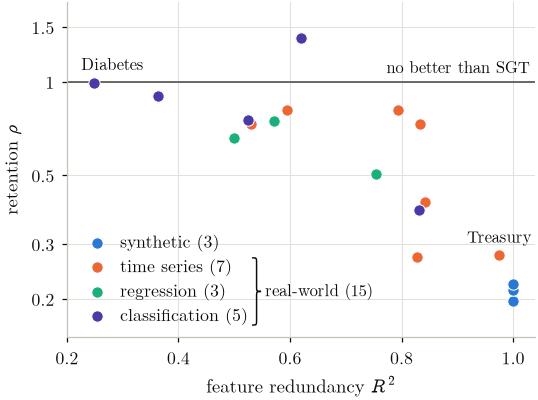

In [10]:
import io
import contextlib
from src.data import get_data, preprocess
from src.constants import DATASETS

KEY2ID = {v: k for k, v in DATASETS.items()}


def load_X(name):
    with contextlib.redirect_stderr(io.StringIO()), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return np.asarray(preprocess(get_data(KEY2ID[name]), name)['data'], float)


def redundancy(X):
    """Mean leave-one-column-out OLS R^2 of the standardised data."""
    X = (X - X.mean(0)) / (X.std(0) + 1e-12)
    r2 = []
    for j in range(X.shape[1]):
        A = np.c_[np.delete(X, j, 1), np.ones(len(X))]
        coef, *_ = np.linalg.lstsq(A, X[:, j], rcond=None)
        r2.append(1 - (X[:, j] - A @ coef).var() / X[:, j].var())
    return float(np.mean(r2))


# retention per dataset: geometric mean over rates, distances and dimensions (MAR; K and sgt from the growth cells)
rho_ds = np.exp(np.log(pd.concat([K, sgt], axis=1, join='inner').eval('knn / sgt')).groupby('dataset').mean())
RED = pd.DataFrame({'rho': rho_ds, 'R2': pd.Series({d: redundancy(load_X(d)) for d in rho_ds.index}),
                    'family': rho_ds.index.map(family)}).sort_values('rho')

syn, real = RED[RED.family == 'Synthetic'], RED[RED.family == 'Real-world']
mw = stats.mannwhitneyu(syn.rho, real.rho, method='exact')
sp_real = stats.spearmanr(real.R2, np.log(real.rho))
display(RED.round(3))
print(f'rho median: synthetic {syn.rho.median():.2f}, real-world {real.rho.median():.2f} '
      f'(range {real.rho.min():.2f}-{real.rho.max():.2f}); every manifold below every real dataset: {syn.rho.max() < real.rho.min()}; '
      f'Mann-Whitney p = {mw.pvalue:.2g}')
print(f'Spearman R2 vs log rho (real-world): r_s = {sp_real.statistic:.2f} (p = {sp_real.pvalue:.2g}, n = {len(real)})')

# ---- figure ----
COL = 0.62 * FULL
fig, ax = plt.subplots(figsize=(COL, COL * 0.72))
ax.axhline(1, color=INK2, lw=0.8, zorder=1)
ax.text(1.03, 1.04, 'no better than SGT', fontsize=SMALL, color=INK, va='bottom', ha='right')
# colour: synthetic vs the three real-world types (fixed slots, validated colour-blind safe)
TYPE = {'manifold': ('synthetic', BLUE), 'time_series': ('time series', ORANGE),
        'regression': ('regression', AQUA), 'classification': ('classification', VIOLET)}
RED['type'] = RED.index.map(DATASET_TYPE_MAP)
for t, (lab, col) in TYPE.items():
    s_ = RED[RED.type == t]
    ax.scatter(s_.R2, s_.rho, s=30, color=col, edgecolor='white', linewidth=0.5, zorder=3, label=f'{lab} ({len(s_)})')
# label the two extremes named in the text
for d, lab, (dx, dy, ha) in [('treasury', 'Treasury', (0, 6, 'center')), ('diabetes', 'Diabetes', (9, 6, 'center'))]:
    ax.annotate(lab, (RED.R2[d], RED.rho[d]), xytext=(dx, dy), textcoords='offset points', fontsize=SMALL, color=INK, ha=ha)
ax.set_yscale('log')
ax.set_yticks([0.2, 0.3, 0.5, 1.0, 1.5], ['0.2', '0.3', '0.5', '1', '1.5'])
ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlim(0.2, 1.04); ax.set_ylim(0.15, 1.8)
ax.set_xlabel(r'feature redundancy $R^2$')
ax.set_ylabel(r'retention $\rho$')
leg = ax.legend(loc='lower left', handletextpad=0.3, borderaxespad=0.3, labelspacing=0.35)


def legend_brace(ax, texts, label, w_px=9, r_px=5, pad_px=4):
    """Curly brace to the right of the given legend texts, with a label (all in axes coordinates)."""
    fig = ax.figure
    fig.canvas.draw()
    to_ax = ax.transAxes.inverted()
    boxes = [t.get_window_extent() for t in texts]
    x0 = max(b.x1 for b in boxes) + pad_px
    top, bot = max(b.y1 for b in boxes), min(b.y0 for b in boxes)
    mid = (top + bot) / 2
    w, r = w_px, r_px
    px = [(x0, top), (x0 + w / 2, top), (x0 + w / 2, top), (x0 + w / 2, top - r),
          (x0 + w / 2, mid + r),
          (x0 + w / 2, mid), (x0 + w / 2, mid), (x0 + w, mid),
          (x0 + w / 2, mid), (x0 + w / 2, mid), (x0 + w / 2, mid - r),
          (x0 + w / 2, bot + r),
          (x0 + w / 2, bot), (x0 + w / 2, bot), (x0, bot)]
    codes = [mpl.path.Path.MOVETO] + [mpl.path.Path.CURVE4] * 3 + [mpl.path.Path.LINETO] \
        + [mpl.path.Path.CURVE4] * 6 + [mpl.path.Path.LINETO] + [mpl.path.Path.CURVE4] * 3
    verts = to_ax.transform(px)
    ax.add_patch(mpl.patches.PathPatch(mpl.path.Path(verts, codes), transform=ax.transAxes, fill=False,
                                       lw=0.7, edgecolor=INK, clip_on=False))
    tx, ty = to_ax.transform((x0 + w + pad_px, mid))
    ax.text(tx, ty, label, transform=ax.transAxes, va='center', ha='left', fontsize=SMALL, color=INK)


legend_brace(ax, leg.get_texts()[1:], f'real-world ({(RED.family == "Real-world").sum()})')
save_fig(fig, 'redundancy_retention')
plt.show()

## Table: missingness mechanism (RQ5)

$k$NN, VR, all three mechanisms, 13 rates (1–40%). Per (dataset, mechanism), log-ratios are averaged over rates, distances and dimensions; entries are medians over datasets (back-transformed). The retention $\rho = d_\mathrm{IMP}/d_\mathrm{SGT}$ decomposes as $(d_\mathrm{IMP}/d_\mathrm{RS}) / (d_\mathrm{SGT}/d_\mathrm{RS})$: the imputation against the noise floor, and the strength of the shuffled reference. $p$: Friedman test across mechanisms on the real-world datasets. Rows "1–5%" and "25–40%" average only those rates. Writes `mechanism.tex`.

Numbers for the text (real-world): per measure, the MNAR/MCAR ratio of $d_\mathrm{kNN}$ and of $d_\mathrm{SGT}$ (median of per-dataset ratios, log-averaged over rates) and the number of datasets in which MNAR is lower; the same ratio for RMSE and MAE. Wilcoxon, Holm over all 26 tests. Exact zeros enter with the same $\varepsilon$ as everywhere else.

In [11]:
MECH_NAME = {MCAR: 'MCAR', MAR: 'MAR', MNAR: 'MNAR'}
MECHS = ['MCAR', 'MAR', 'MNAR']
idx = ['dataset', 'missingness_type', 'missing_rate', 'metric', 'dimension']

knn_all = smooth(raw['topological_metrics_mr'])
knn_all = knn_all[(knn_all.tda_method == VR) & (knn_all.imputation_method == KNN)].set_index(idx).v.rename('knn')
refs = base[base.tda_method == VR].pivot_table(index=idx, columns='imputation_method', values='v')[[SGT, RS]]
M = pd.concat([knn_all, refs], axis=1, join='inner').reset_index()
M['rho'] = np.log(M.knn / M[SGT]); M['imp_rs'] = np.log(M.knn / M[RS]); M['sgt_rs'] = np.log(M[SGT] / M[RS])
M['family'] = M.dataset.map(family); M['mech'] = M.missingness_type.map(MECH_NAME)

# raw error of the same imputations (features are z-scored, so RMSE is in SD units and comparable across datasets)
RM = pd.read_csv(RES / 'comparison_metrics_results.csv')
RM = RM[(RM.imputation_method == KNN) & RM.dataset.isin(M.dataset.unique())].assign(
    rmse=lambda d: np.log(d.root_mean_square_error), mae=lambda d: np.log(d.mean_absolute_error), family=lambda d: d.dataset.map(family),
    mech=lambda d: d.missingness_type.map(MECH_NAME))


def per_dataset(df, col):
    """datasets x mechanisms matrix of mean log-ratios."""
    return df.groupby(['dataset', 'mech'])[col].mean().unstack()[MECHS]


FAMS = ['Synthetic', 'Real-world']
ROWS = [('rho', None, r'$\rho = d_{\TOPO} / d_{\SGT}$'),
        ('rho', 'count', r'\quad datasets with $\rho > 1$'),
        ('rho', (1, 5), r'\quad 1--5\% missing'),
        ('rho', (25, 40), r'\quad 25--40\% missing'),
        ('imp_rs', None, r'$d_{\TOPO} / d_{\RS}$'),
        ('sgt_rs', None, r'$d_{\SGT}/d_{\RS}$'),
        ('rmse', None, r'RMSE'),
        ('mae', None, r'MAE')]

lines, n_fam = [], {}
for i, (col, kind, label) in enumerate(ROWS):
    cells, p = [], ''
    for F in FAMS:
        df = (RM if col in ('rmse', 'mae') else M)
        df = df[df.family == F]
        if isinstance(kind, tuple):
            df = df[df.missing_rate.between(*kind)]
        X = per_dataset(df, col)
        n_fam[F] = len(X)
        if kind == 'count':
            cells += [f'{int((X[m] > 0).sum())}/{len(X)}' for m in MECHS]
        else:
            cells += [f'{np.exp(X[m].median()):.2f}' for m in MECHS]
        if F == 'Real-world' and kind is None:
            fp = stats.friedmanchisquare(*[X[m] for m in MECHS]).pvalue
            p = '$<.001$' if fp < 1e-3 else f'${fp:.2f}$'.replace('0.', '.')
    if i in (4, 6):
        lines.append(r'        \midrule')
    lines.append(f'        {label} & ' + ' & '.join(cells + [p]) + r' \\')

save_tex(rf"""\begin{{table}}[t]
    \centering
    \caption{{Impact of the missingness mechanism ($k$NN, VR, 1--40\%). Median geometric mean across datasets, missing rates, distances, and dimensions. $p$: Friedman test across mechanisms (real-world).}}
    \label{{tab:mechanism}}
    \small
    \setlength{{\tabcolsep}}{{10pt}}
    \begin{{tabular}}{{l ccc cccc}}
        \toprule
        & \multicolumn{{3}}{{c}}{{Synthetic ({n_fam['Synthetic']})}} & \multicolumn{{4}}{{c}}{{Real-world ({n_fam['Real-world']})}} \\
        \cmidrule(lr){{2-4}}\cmidrule(lr){{5-8}}
        & MCAR & MAR & MNAR & MCAR & MAR & MNAR & $p$ \\
        \midrule
{chr(10).join(lines)}
        \bottomrule
    \end{{tabular}}
\end{{table}}""", 'mechanism')

# MNAR vs MCAR per measure (real-world): kNN, SGT, and the raw errors
Mr = M[M.family == 'Real-world'].assign(l_knn=lambda d: np.log(d.knn), l_sgt=lambda d: np.log(d[SGT]))
mech_rows = []
for q, col in [('kNN', 'l_knn'), ('SGT', 'l_sgt')]:
    for m, d in FEATURES:
        X = per_dataset(Mr[(Mr.metric == m) & (Mr.dimension == d)], col)
        mech_rows.append(dict(q=q, measure=f'{LABEL_TOPO[m]} H{d}', ratio=np.exp((X.MNAR - X.MCAR).median()),
                              lower=f'{(X.MNAR < X.MCAR).sum()}/{len(X)}', p=signed_rank((X.MNAR - X.MCAR).values),
                              friedman=stats.friedmanchisquare(*X.T.values).pvalue))
for col, name in [('rmse', 'RMSE'), ('mae', 'MAE')]:
    X = per_dataset(RM[RM.family == 'Real-world'], col)
    mech_rows.append(dict(q='raw', measure=name, ratio=np.exp((X.MNAR - X.MCAR).median()),
                          lower=f'{(X.MNAR < X.MCAR).sum()}/{len(X)}', p=signed_rank((X.MNAR - X.MCAR).values),
                          friedman=stats.friedmanchisquare(*X.T.values).pvalue))
MECH_TXT = pd.DataFrame(mech_rows)
MECH_TXT['p_holm'] = holm(MECH_TXT.p)
display(MECH_TXT.round(3))
for q in ('kNN', 'SGT'):
    x = MECH_TXT[MECH_TXT.q == q]
    print(f'{q} MNAR/MCAR: {x.ratio.min():.2f}-{x.ratio.max():.2f}, max Holm p = {x.p_holm.max():.3f}')

/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/mechanism.tex


```latex
\begin{table}[t]
    \centering
    \caption{Impact of the missingness mechanism ($k$NN, VR, 1--40\%). Median geometric mean across datasets, missing rates, distances, and dimensions. $p$: Friedman test across mechanisms (real-world).}
    \label{tab:mechanism}
    \small
    \setlength{\tabcolsep}{10pt}
    \begin{tabular}{l ccc cccc}
        \toprule
        & \multicolumn{3}{c}{Synthetic (3)} & \multicolumn{4}{c}{Real-world (15)} \\
        \cmidrule(lr){2-4}\cmidrule(lr){5-8}
        & MCAR & MAR & MNAR & MCAR & MAR & MNAR & $p$ \\
        \midrule
        $\rho = d_{\TOPO} / d_{\SGT}$ & 0.05 & 0.21 & 0.37 & 0.57 & 0.73 & 1.33 & $<.001$ \\
        \quad datasets with $\rho > 1$ & 0/3 & 0/3 & 0/3 & 0/15 & 1/15 & 11/15 &  \\
        \quad 1--5\% missing & 0.03 & 0.38 & 0.92 & 0.51 & 0.79 & 1.80 &  \\
        \quad 25--40\% missing & 0.09 & 0.10 & 0.12 & 0.51 & 0.66 & 0.89 &  \\
        \midrule
        $d_{\TOPO} / d_{\RS}$ & 0.36 & 0.41 & 0.45 & 0.66 & 0.58 & 0.69 & $.42$ \\
        $d_{\SGT}/d_{\RS}$ & 6.32 & 2.07 & 1.04 & 1.08 & 0.74 & 0.49 & $<.001$ \\
        \midrule
        RMSE & 0.03 & 0.20 & 0.21 & 0.18 & 0.23 & 0.33 & $<.001$ \\
        MAE & 0.01 & 0.05 & 0.05 & 0.03 & 0.05 & 0.08 & $<.001$ \\
        \bottomrule
    \end{tabular}
\end{table}
```

,q,measure,ratio,lower,p,friedman,p_holm
0,kNN,WS H0,1.274,6/15,0.277,0.085,1.000
1,kNN,WS H1,1.095,5/15,0.934,0.001,1.000
2,kNN,WS H2,1.047,5/15,0.847,0.000,1.000
3,kNN,BN H0,1.032,7/15,0.762,0.247,1.000
4,kNN,BN H1,0.954,8/15,0.934,0.627,1.000
5,kNN,BN H2,0.919,10/15,0.330,0.189,1.000
6,kNN,PL H0,0.400,9/15,0.026,0.074,0.307
7,kNN,PL H1,1.161,6/15,0.421,0.074,1.000
8,kNN,PL H2,0.970,9/15,0.421,0.420,1.000
9,kNN,PI H0,0.842,9/15,0.762,0.344,1.000


kNN MNAR/MCAR: 0.40-1.27, max Holm p = 1.000
SGT MNAR/MCAR: 0.05-0.68, max Holm p = 0.002


## Table: filtrations (RQ6)

$k$NN, MAR, 5/10/25%, VR vs the DTM-weighted Rips filtration and the kernel distance (KD). Elasticity $\beta$ per (dataset, filtration, measure) as in the growth table, but over three rates; entries: median over datasets (lower = more robust; bold = lowest). Raw distances are not comparable across filtrations (KD is bounded by $\sqrt2$), the elasticity is scale-free. Real-world stars: two-sided Wilcoxon of DTM and KD against VR, Holm over the 24 tests; synthetic: median only ($n = 3$). Mean rank: rank of the three filtrations per (dataset, measure), averaged per dataset, then re-ranked per dataset and averaged (Friedman mean rank, as in the imputation table); Friedman test and Holm-corrected pairwise Wilcoxon on these per-dataset ranks. Writes `filtration.tex`.

In [12]:
DTM, KD = 'distance_to_a_measure_chazal', 'kernel_distance'
FILT = {VR: 'VR', DTM: 'DTM', KD: 'KD'}

fl = smooth(raw['topological_metrics_filtration'])
fl = fl[(fl.imputation_method == KNN) & (fl.missingness_type == MAR)]
bf = (fl.groupby(['dataset', 'metric', 'dimension', 'tda_method']).apply(elasticity)
      .unstack('tda_method').rename(columns=FILT)[list(FILT.values())].dropna())
bf_fam = bf.index.get_level_values('dataset').map(family)

# consensus: rank of the filtrations per (dataset, measure), averaged per dataset, then Friedman mean ranks
# of these per-dataset scores (as for the imputers)
R_filt = bf.rank(axis=1).groupby('dataset').mean()
r_fam = R_filt.index.map(family)
cons = {}
for F in ('Synthetic', 'Real-world'):
    X = R_filt[r_fam == F]
    cons[F] = dict(rank=mean_ranks(X), n=len(X), p=stats.friedmanchisquare(*[X[c] for c in X]).pvalue,
                   pairs=pairwise_wilcoxon(X) if len(X) >= 5 else None)

# per measure: medians by family, real-world DTM and KD vs VR
p_vs = {}
for m, d in FEATURES:
    x = bf.xs((m, d), level=('metric', 'dimension'))
    x = x[x.index.map(family) == 'Real-world']
    for f in ('DTM', 'KD'):
        p_vs[(m, d, f)] = signed_rank((x[f] - x['VR']).values)
p_vs = dict(zip(p_vs, holm(list(p_vs.values()))))

def p_tex(p):
    return '< .001' if p < 1e-3 else f'= {p:.2f}'.replace('0.', '.')


rows = []
for m, d in FEATURES:
    row = [MACRO[m], rf'\Hd{{{d}}}']
    for F in ('Synthetic', 'Real-world'):
        x = bf[bf_fam == F].xs((m, d), level=('metric', 'dimension')).median()
        for f in FILT.values():
            v = f'{x[f] + 0:.2f}'.replace('-0.00', '0.00').replace('-', '$-$')
            v = rf'\textbf{{{v}}}' if np.isclose(x[f], x.min()) else v
            if F == 'Real-world' and f != 'VR' and stars(p_vs[(m, d, f)]):
                v += rf'\sig{{{stars(p_vs[(m, d, f)])}}}'
            row.append(v)
    rows.append(row)


rank_cells = []
for F in ('Synthetic', 'Real-world'):
    rk = cons[F]['rank']
    rank_cells += [rf'\textbf{{{rk[f]:.2f}}}' if np.isclose(rk[f], rk.min()) else f'{rk[f]:.2f}' for f in FILT.values()]
n_syn, n_real = cons['Synthetic']['n'], cons['Real-world']['n']

save_tex(rf'''\begin{{table}}[t]
    \centering
    \caption{{Filtration robustness ($k$NN, MAR, 5--25\%). Median elasticity $\beta$ of topological error. Stars: Wilcoxon vs.\ VR, Holm-corrected. Mean ranks: Friedman $p {p_tex(cons['Synthetic']['p'])}$ (synthetic), $p {p_tex(cons['Real-world']['p'])}$ (real).}}
    \label{{tab:filtration}}
    \small
    \setlength{{\tabcolsep}}{{10pt}}
    \begin{{tabular}}{{r@{{\,}}l ccc ccc}}
        \toprule
        \multicolumn{{2}}{{c}}{{}} & \multicolumn{{3}}{{c}}{{Synthetic ({n_syn})}} & \multicolumn{{3}}{{c}}{{Real-world ({n_real})}} \\
        \cmidrule(lr){{3-5}}\cmidrule(lr){{6-8}}
        \multicolumn{{2}}{{c}}{{Measure}} & VR & DTM & KD & VR & DTM & KD \\
        \midrule
{align_rows(rows)}
        \midrule
        \multicolumn{{2}}{{l}}{{Mean rank $\downarrow$}} & {' & '.join(rank_cells)} \\
        \bottomrule
    \end{{tabular}}
\end{{table}}''', 'filtration')

# numbers for the text
for F in ('Synthetic', 'Real-world'):
    print(F, cons[F]['rank'].round(2).to_dict(), 'Friedman p =', f"{cons[F]['p']:.2g}")
print(cons['Real-world']['pairs'][['a', 'b', 'diff', 'p_holm']].round(4).to_string(index=False))

/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/filtration.tex


```latex
\begin{table}[t]
    \centering
    \caption{Filtration robustness ($k$NN, MAR, 5--25\%). Median elasticity $\beta$ of topological error. Stars: Wilcoxon vs.\ VR, Holm-corrected. Mean ranks: Friedman $p = .72$ (synthetic), $p < .001$ (real).}
    \label{tab:filtration}
    \small
    \setlength{\tabcolsep}{10pt}
    \begin{tabular}{r@{\,}l ccc ccc}
        \toprule
        \multicolumn{2}{c}{} & \multicolumn{3}{c}{Synthetic (3)} & \multicolumn{3}{c}{Real-world (15)} \\
        \cmidrule(lr){3-5}\cmidrule(lr){6-8}
        \multicolumn{2}{c}{Measure} & VR & DTM & KD & VR & DTM & KD \\
        \midrule
        \WS & \Hd{0} & \textbf{0.35} & 0.63             & 0.37          & 1.18          & \textbf{0.40}\sig{**} & 1.35 \\
        \WS & \Hd{1} & 0.65          & 0.81             & \textbf{0.63} & 0.71          & \textbf{0.11}\sig{**} & 0.83 \\
        \WS & \Hd{2} & 0.32          & \textbf{$-$0.71} & 0.08          & 0.47          & \textbf{$-$0.19}      & 0.61 \\
        \BN & \Hd{0} & 0.37          & 0.74             & \textbf{0.35} & 0.48          & 0.66                  & \textbf{0.46} \\
        \BN & \Hd{1} & 0.65          & 0.77             & \textbf{0.42} & \textbf{0.11} & 0.17                  & 0.30 \\
        \BN & \Hd{2} & 0.00          & \textbf{$-$0.46} & 0.02          & 0.15          & \textbf{$-$0.03}      & 0.51 \\
        \PL & \Hd{0} & \textbf{0.40} & 0.70             & 0.47          & 1.39          & \textbf{1.30}         & 2.13 \\
        \PL & \Hd{1} & 0.39          & \textbf{0.36}    & 0.71          & 0.17          & \textbf{0.03}         & 0.36 \\
        \PL & \Hd{2} & 0.42          & \textbf{$-$0.02} & 0.02          & 0.08          & \textbf{$-$0.08}      & 0.28 \\
        \PI & \Hd{0} & 1.10          & 0.50             & \textbf{0.36} & 0.54          & \textbf{0.30}         & 0.33 \\
        \PI & \Hd{1} & 0.39          & \textbf{$-$0.11} & 0.73          & 0.89          & \textbf{0.51}         & 1.26 \\
        \PI & \Hd{2} & 0.37          & \textbf{$-$0.25} & 0.32          & 1.31          & \textbf{0.38}         & 1.21 \\
        \midrule
        \multicolumn{2}{l}{Mean rank $\downarrow$} & 2.00 & 2.33 & \textbf{1.67} & 2.10 & \textbf{1.23} & 2.67 \\
        \bottomrule
    \end{tabular}
\end{table}
```

Synthetic {'KD': 1.67, 'VR': 2.0, 'DTM': 2.33} Friedman p = 0.72
Real-world {'DTM': 1.23, 'VR': 2.1, 'KD': 2.67} Friedman p = 0.00035
  a   b    diff  p_holm
 VR DTM  0.6667  0.0126
 VR  KD -0.6250  0.0437
DTM  KD -0.9091  0.0002


## Table: scale of the kernel-distance filtration (appendix, RQ6)

Per dataset, on the clean standardised data: Silverman's-rule bandwidth $h = (n(d+2)/4)^{-1/(d+4)}$ as in `src/tda.py`, median pairwise Euclidean distance, share of point pairs whose kernel distance $D_K = \sqrt{2 - 2\exp(-\|x-y\|^2/2h^2)}$ exceeds $0.99\sqrt2$, and the median nearest-neighbour kernel distance relative to the ceiling $\sqrt2$. Sorted by the share at the ceiling. Uses `load_X` from the redundancy cell. Writes `kd.tex`.

In [13]:
from sklearn.metrics import pairwise_distances
from src.constants import LABEL as NAME   # descriptive dataset names (LABEL is taken in this notebook)

TYPE_NAME = {'manifold': 'Synthetic Manifold', 'time_series': 'Time series', 'regression': 'Regression', 'classification': 'Classification'}

kd_rows = {}
for name in sorted(bf.index.get_level_values('dataset').unique()):
    X = load_X(name)
    n, d = X.shape
    h = (n * (d + 2) / 4) ** (-1 / (d + 4))
    E = pairwise_distances(X); iu = np.triu_indices(n, 1)
    D = np.sqrt(np.clip(2 - 2 * np.exp(-E ** 2 / (2 * h ** 2)), 0, None))
    kd_rows[name] = dict(type=TYPE_NAME[DATASET_TYPE_MAP[name]], h=h, dist=np.median(E[iu]),
                         ceil=np.mean(D[iu] > 0.99 * np.sqrt(2)) * 100,
                         nn=np.median(np.sort(D, 1)[:, 1]) / np.sqrt(2))
KDS = pd.DataFrame(kd_rows).T.sort_values('ceil')

rows = [[NAME[name].replace('&', r'\&'), r.type, f'{r.h:.2f}', f'{r.dist:.2f}', f'{r.ceil:.1f}\\%', f'{r.nn:.2f}']
        for name, r in KDS.iterrows()]
save_tex(rf'''\begin{{table}}[h]
    \centering
    \caption{{Kernel-distance scale with Silverman's bandwidth $h$: median pairwise Euclidean distance, share of pairs with kernel distance above $0.99 \cdot \sqrt{2}$, and median nearest-neighbor kernel distance relative to $\sqrt{2}$.}}
    \label{{tab:kd}}
    \small
    \setlength{{\tabcolsep}}{{10pt}}
    \begin{{tabular}}{{l l cccc}}
        \toprule
        Dataset & Type & $h$ & Median dist. & Pairs at ceiling & $\dfrac{{\operatorname{{1-NN}}}}{{\sqrt2}}$ \\
        \midrule
{align_rows(rows)}
        \bottomrule
    \end{{tabular}}
\end{{table}}''', 'kd')

# ranges for the text
print(f"h {KDS.h.min():.2f}-{KDS.h.max():.2f}; median distance {KDS.dist.min():.1f}-{KDS.dist.max():.1f}; "
      f"pairs at ceiling {KDS.ceil.min():.1f}-{KDS.ceil.max():.1f}%")

/home/mno/Documents/kde/tda-imputation-robustness/figures/tmlr/kd.tex


```latex
\begin{table}[h]
    \centering
    \caption{Kernel-distance scale with Silverman's bandwidth $h$: median pairwise Euclidean distance, share of pairs with kernel distance above $0.99 \cdot \sqrt2$, and median nearest-neighbor kernel distance relative to $\sqrt2$.}
    \label{tab:kd}
    \small
    \setlength{\tabcolsep}{10pt}
    \begin{tabular}{l l cccc}
        \toprule
        Dataset & Type & $h$ & Median dist. & Pairs at ceiling & $\dfrac{\operatorname{1-NN}}{\sqrt2}$ \\
        \midrule
        Treasury                    & Time series        & 0.64 & 4.17 & 84.8\% & 0.10 \\
        Indian Stock Market         & Time series        & 0.47 & 3.27 & 88.6\% & 0.14 \\
        Stock                       & Time series        & 0.55 & 4.28 & 91.2\% & 0.27 \\
        Hungarian Chickenpox        & Time series        & 0.72 & 5.68 & 92.1\% & 1.00 \\
        Sphere                      & Synthetic Manifold & 0.70 & 6.34 & 93.8\% & 0.21 \\
        Weather Izmir               & Time series        & 0.53 & 3.61 & 94.8\% & 0.71 \\
        Swiss Roll                  & Synthetic Manifold & 0.70 & 5.83 & 95.0\% & 0.21 \\
        Debutanizer                 & Classification     & 0.46 & 3.15 & 95.0\% & 0.46 \\
        Torus                       & Synthetic Manifold & 0.70 & 5.78 & 95.9\% & 0.26 \\
        RMFTSA LA Data              & Time series        & 0.59 & 3.94 & 96.3\% & 0.89 \\
        Diabetes                    & Classification     & 0.53 & 3.63 & 97.7\% & 0.90 \\
        Concrete Data               & Regression         & 0.54 & 3.95 & 97.8\% & 0.45 \\
        Air Quality and Pollution   & Classification     & 0.48 & 3.52 & 97.9\% & 0.83 \\
        Gender Recognition by Voice & Classification     & 0.67 & 5.42 & 98.4\% & 0.81 \\
        Boston Weather Data         & Time series        & 0.66 & 5.54 & 98.7\% & 0.85 \\
        Red Wine Quality            & Regression         & 0.57 & 4.06 & 98.7\% & 0.80 \\
        Football Player Position    & Classification     & 0.54 & 4.06 & 99.2\% & 0.90 \\
        White Wine Quality          & Regression         & 0.52 & 4.25 & 99.7\% & 0.78 \\
        \bottomrule
    \end{tabular}
\end{table}
```

h 0.46-0.72; median distance 3.1-6.3; pairs at ceiling 84.8-99.7%
